# 07 — Un seul SFT : QA et triage mélangés

## 1. Hypothèse et comparaison

Le SFT successif a spécialisé le modèle en triage mais dégradé ses réponses QA. Je teste une autre organisation : **un nouveau LoRA, entraîné dès le départ sur les deux tâches**.

```text
Socle Qwen3-1.7B-Base ── QA puis triage ── SFT v3 déjà mesuré
                    └── QA + triage ──── nouvelle expérience
                                           ↓
                              validation QA / validation triage
```

Je conserve les partitions v3, le format des réponses et les réglages de génération. Je change la recette d'entraînement : cette comparaison ne permet donc pas d'attribuer tout écart au seul ordre des exemples. Le test final a déjà été consulté ; **je ne le réutilise pas pour choisir les paramètres ou le checkpoint**. Une confirmation finale indépendante demanderait de nouveaux cas.

| Partition | QA | Triage | Total | Français / anglais |
|---|---:|---:|---:|---:|
| Entraînement | 2 098 | 1 888 | 3 986 | 1 993 / 1 993 |
| Validation | 262 | 238 | 500 | 250 / 250 |

Chaque exemple apparaît une fois par époque. Je mélange les tâches sans sur-échantillonnage : environ 53 % QA et 47 % triage. Une part d'exemples n'est pas une part de tokens. Le contrôle CPU avec le tokenizer figé compte **417 901 tokens QA et 110 042 tokens triage** dans le train : environ 79 % des tokens supervisés viennent du QA. Ce comptage ne mesure pas à lui seul la contribution exacte au gradient. Je le recalcule dans Colab ; je conserve cette première recette sans pondération supplémentaire.

## 2. Protocole fixé avant l'exécution

- Socle et tokenizer à la même révision que les expériences précédentes ; **aucun adaptateur initial**.
- LoRA : rang 16, alpha 32, dropout 0,05 ; BF16 ; contexte maximal 5 120 tokens, sans troncature silencieuse.
- Trois époques, learning rate 0,0001, batch effectif 16, seed 3407.
- Sauvegarde et mesure de la loss tous les 250 pas, soit environ une époque. Je conserve les trois checkpoints.
- Génération sur validation pour chaque checkpoint : QA 256 tokens, triage 192, batch 32, sans échantillonnage, arrêt EOS natif.
- Aucun remplacement automatique du modèle déployé. Le meilleur checkpoint selon la loss mixte est conservé, mais sa pertinence doit être examinée tâche par tâche.

**Première expérience terminée.** Ses sorties sont conservées ci-dessous ; son lancement est désormais désactivé par défaut. La poursuite jusqu’à l’époque 10 est également terminée. Son analyse figure en section 9 ; les deux cellules GPU sont désactivées par défaut pour éviter une réexécution involontaire.


**Repère de lecture · 07 · Préserver QA et triage**

Je compare un SFT commun aux deux tâches, puis sa poursuite jusqu’à dix époques. Les résultats sont acquis : l’époque 3 reste ma référence expérimentale équilibrée ; la section 9 explique pourquoi prolonger ne suffit pas.

[← 06 · Vérifier la chaîne API](06_verification_vllm_colab.ipynb) · [Sommaire du projet](../README.md) · [08 · Tester des préférences ciblées →](08_dpo_triage_cible_colab.ipynb)

---


In [ ]:
REJOUER_ESSAI_INITIAL = False  # Résultats déjà acquis ; ne pas repartir du socle.
import hashlib
import json
import math
import os
from pathlib import Path
import shutil
import sqlite3
import subprocess
import sys
import time
import traceback
import zipfile
from collections import Counter
from datetime import datetime, timezone

from google.colab import drive, runtime

REVISION = "ea980cb0a6c2ae4b936e82123acc929f1cec04c1"
ARCHIVE = "ocr14_sft_mixte_20261106.zip"
SHA_ARCHIVE = "937474674b569ce0d94184e3a45fa30a85c1fbab6cecb0af65f69f519315f531"
EPOCHS, MICRO_BATCH, ACCUMULATION = 3, 4, 4
LONGUEUR, LEARNING_RATE, SEED = 5120, 1e-4, 3407


def sha256(fichier):
    """Calcule une empreinte sans charger les checkpoints en mémoire."""
    h = hashlib.sha256()
    with Path(fichier).open("rb") as flux:
        for bloc in iter(lambda: flux.read(1024 * 1024), b""):
            h.update(bloc)
    return h.hexdigest()


def lire_jsonl(fichier):
    return [json.loads(l) for l in Path(fichier).read_text().splitlines() if l.strip()]


def executer(commande, journal):
    """Conserve le journal complet et affiche sa fin en cas d'échec."""
    print(f"Étape : {journal.name}", flush=True)
    with journal.open("a", encoding="utf-8") as flux:
        with subprocess.Popen(commande, cwd=RACINE, stdout=subprocess.PIPE,
                              stderr=subprocess.STDOUT, text=True,
                              env={**os.environ, "PYTHONUNBUFFERED": "1"}) as processus:
            for ligne in processus.stdout:
                flux.write(ligne)
                flux.flush()
                # Les métriques Trainer et les compteurs d'inférence suffisent à suivre le run.
                if "'loss':" in ligne or "'eval_loss':" in ligne or ligne.strip().replace("/", "").isdigit():
                    print(ligne.strip(), flush=True)
            code_retour = processus.wait()
    if code_retour:
        print(journal.read_text()[-8000:])
        raise RuntimeError(f"Échec ; consulter {journal.name}")


def scores(qa, triage):
    """Sépare qualité QA, classement du triage et rappel des urgences."""
    return {
        "accuracy_qcm": qa["qcm"]["accuracy"],
        "f1_lexical": qa["reponses_ouvertes"]["f1_lexical_moyen"],
        "macro_f1_priorite": triage["priorite"]["macro_f1"],
        "rappel_maximale": triage["priorite"]["rappel_par_classe"]["maximale"],
        "accuracy_esi": triage["esi"]["accuracy"],
        "esi_analysable": triage["taux_sortie_esi_valide"],
    }


## 3. Exécution suivie et sauvegardée

Je contrôle les empreintes des sources et l'absence de chevauchement entre train et validation. Le script `training/preparer_mixte.py` réalise uniquement cette union ; `training/entrainer_lora.py` entraîne le nouveau LoRA. Les scripts `evaluation/inference.py` et `evaluation/evaluer.py` restent communs aux variantes.

Les checkpoints et journaux sont écrits sur Drive au fil de l'exécution. MLflow utilise une base SQLite locale, sauvegardée proprement sur Drive à la fin. Si une étape échoue, les productions disponibles sont conservées. Une extinction brutale de la VM peut néanmoins perdre les dernières écritures non synchronisées.

La génération sur les trois checkpoints représente **1 500 réponses**, en plus de l'entraînement. Le temps total sera mesuré : je ne le déduis pas uniquement de la vitesse du GPU.


In [ ]:
if REJOUER_ESSAI_INITIAL:
    # Le contrôle GPU précède le montage : cette expérience exige BF16 sur G4/A100.
    if shutil.which("nvidia-smi") is None:
        raise RuntimeError("Sélectionner un GPU G4 ou A100 dans le type d'exécution Colab.")
    GPU = subprocess.check_output(
        ["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"], text=True).strip()
    print("GPU attribué :", GPU)
    drive.mount("/content/drive")
    DRIVE = Path("/content/drive/MyDrive/OCR_PROJET_14")
    paquet = DRIVE / ARCHIVE
    if sha256(paquet) != SHA_ARCHIVE:
        raise ValueError("L'archive d'entrée ne correspond pas au protocole préparé.")
    identifiant = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S")
    RACINE = Path("/content") / f"OCR14_mixte_{identifiant}"
    RACINE.mkdir(exist_ok=False)
    with zipfile.ZipFile(paquet) as archive:
        for nom in archive.namelist():
            if not (RACINE / nom).resolve().is_relative_to(RACINE.resolve()):
                raise ValueError("Chemin invalide dans l'archive.")
        archive.extractall(RACINE)
    SORTIES = DRIVE / "experiences" / f"sft_mixte_{identifiant}"
    SORTIES.mkdir(parents=True, exist_ok=False)
    BASE = RACINE / "mlflow.db"
    statut = {"experience": "sft_mixte", "statut": "en_cours", "gpu": GPU,
              "revision": REVISION, "archive_sha256": SHA_ARCHIVE,
              "test_final": "non_lu", "deploiement": "inchange"}
    debut = time.perf_counter()

    try:
        # Je garde les scripts et les données exacts utilisés avec les résultats.
        shutil.copy2(paquet, SORTIES / ARCHIVE)
        executer([sys.executable, "-m", "pip", "uninstall", "-y", "torchao"], SORTIES / "installation.log")
        executer([sys.executable, "-m", "pip", "install", "-q",
                  "transformers==5.22.1", "peft==0.21.2", "accelerate==1.15.0",
                  "mlflow==3.17.2", "scikit-learn==1.9.1"], SORTIES / "installation.log")
        import torch
        import mlflow
        from transformers import AutoTokenizer
        sys.path.insert(0, str(RACINE))
        from training.preparer_mixte import construire_mixte
        from training.format_sft import encoder_exemple

        if not torch.cuda.is_available() or not torch.cuda.is_bf16_supported():
            raise RuntimeError("GPU CUDA compatible BF16 requis.")
        sources = RACINE / "data/processed/partitions_v3"
        mixte = SORTIES / "donnees_mixtees"
        manifeste = construire_mixte(sources, mixte, SEED)
        print(json.dumps(manifeste["splits"], ensure_ascii=False, indent=2))
        pas_epoque = math.ceil(math.ceil(manifeste["splits"]["train"]["nombre"] / MICRO_BATCH) / ACCUMULATION)
        tokenizer = AutoTokenizer.from_pretrained("Qwen/Qwen3-1.7B-Base", revision=REVISION)
        tokens = {}
        for split in ("train", "validation"):
            comptes, maximum = Counter(), 0
            for exemple in lire_jsonl(mixte / f"{split}.jsonl"):
                encodage = encoder_exemple(tokenizer, exemple, LONGUEUR)
                comptes[exemple["phase_sft"]] += sum(x != -100 for x in encodage["labels"])
                maximum = max(maximum, encodage["length"])
            tokens[split] = {"tokens_supervises": dict(comptes), "longueur_maximale": maximum}
        (SORTIES / "tokens.json").write_text(json.dumps(tokens, indent=2))
        print("Tokens supervisés et longueurs :", tokens)
        del tokenizer

        entrainement = SORTIES / "entrainement"
        executer([sys.executable, "training/entrainer_lora.py",
                  "--phase", "sft_mixte", "--revision", REVISION, "--dtype", "bfloat16",
                  "--train", str(mixte / "train.jsonl"), "--validation", str(mixte / "validation.jsonl"),
                  "--output", str(entrainement), "--epochs", str(EPOCHS),
                  "--learning-rate", str(LEARNING_RATE), "--max-length", str(LONGUEUR),
                  "--batch-size", str(MICRO_BATCH), "--gradient-accumulation", str(ACCUMULATION),
                  "--checkpoint-steps", str(pas_epoque), "--save-total-limit", str(EPOCHS),
                  "--warmup-steps", "20", "--seed", str(SEED),
                  "--tracking-uri", f"sqlite:///{BASE}", "--experiment", "OCR14-SFT-mixte",
                  "--artifact-location", (SORTIES / "artefacts_mlflow").as_uri(),
                  "--run-name", "mixte-depuis-socle"], SORTIES / "entrainement.log")
        statut["entrainement"] = "termine"
        checkpoints = sorted((entrainement / "checkpoints").glob("checkpoint-*"),
                             key=lambda p: int(p.name.split("-")[-1]))
        if len(checkpoints) != EPOCHS:
            raise RuntimeError(f"{len(checkpoints)} checkpoints disponibles ; {EPOCHS} attendus.")
        mlflow.set_tracking_uri(f"sqlite:///{BASE}")
        mlflow.set_experiment("OCR14-SFT-mixte")
        reference = RACINE / "reference_validation_sft_v3"
        bilan = {"reference_sft_v3": scores(*[
            json.loads((reference / f"{phase}_validation_metriques.json").read_text())
            for phase in ("qa", "triage")])}

        for checkpoint in checkpoints:
            dossier = SORTIES / "validation" / checkpoint.name
            dossier.mkdir(parents=True)
            rapports = {}
            with mlflow.start_run(run_name=f"validation-{checkpoint.name}"):
                mlflow.log_params({"gpu": GPU, "revision": REVISION, "dtype": "bfloat16",
                                   "batch_size": 32, "split": "validation", "stop_token": "eos",
                                   "qa_max_new_tokens": 256, "triage_max_new_tokens": 192,
                                   "epoch": json.loads((checkpoint / "trainer_state.json").read_text())["epoch"],
                                   "adapter_sha256": sha256(checkpoint / "adapter_model.safetensors")})
                for phase, budget in (("qa", 256), ("triage", 192)):
                    predictions = dossier / f"{phase}_validation.jsonl"
                    prefixe = "phase1_qa" if phase == "qa" else "phase2_triage"
                    source = sources / f"{prefixe}_validation.jsonl"
                    precedent = json.loads((reference / f"{phase}_validation_metriques.json").read_text())
                    if sha256(source) != precedent["donnees_sha256"]:
                        raise ValueError("La validation diffère de celle du SFT v3.")
                    executer([sys.executable, "evaluation/inference.py", "--phase", phase,
                              "--split", "validation", "--data-dir", str(sources),
                              "--revision", REVISION, "--dtype", "bfloat16", "--batch-size", "32",
                              "--max-new-tokens", str(budget), "--stop-token", "eos",
                              "--adapter", str(checkpoint), "--output", str(predictions)],
                             dossier / f"{phase}_inference.log")
                    attendus, obtenus = lire_jsonl(source), lire_jsonl(predictions)
                    if [x["id"] for x in obtenus] != [x["id"] for x in attendus]:
                        raise ValueError("Prédictions incomplètes ou désordonnées.")
                    executer([sys.executable, "evaluation/evaluer.py", str(predictions),
                              "--phase", phase, "--split", "validation", "--data-dir", str(sources)],
                             dossier / f"{phase}_metriques.log")
                    rapport = predictions.with_name(predictions.stem + "_metriques.json")
                    rapports[phase] = json.loads(rapport.read_text())
                    mlflow.log_artifact(str(rapport))
                valeurs = scores(rapports["qa"], rapports["triage"])
                bilan[checkpoint.name] = valeurs
                mlflow.log_metrics(valeurs)
            (SORTIES / "comparaison_validation.json").write_text(json.dumps(bilan, indent=2))
            print(checkpoint.name, valeurs, flush=True)
        statut["statut"] = "termine"
        from IPython.display import display, Markdown
        colonnes = list(bilan["reference_sft_v3"])
        tableau = "| Modèle | " + " | ".join(colonnes) + " |\n"
        tableau += "|---|" + "---:|" * len(colonnes) + "\n"
        for nom, valeurs in bilan.items():
            tableau += "| " + nom + " | " + " | ".join(f"{valeurs[c]:.4f}" for c in colonnes) + " |\n"
        display(Markdown(tableau))
    except Exception:
        statut["statut"] = "echec"
        statut["erreur"] = traceback.format_exc()
        print(statut["erreur"])
    finally:
        # Aucune libération automatique si la sauvegarde échoue : je garde la VM récupérable.
        statut["duree_secondes"] = round(time.perf_counter() - debut, 1)
        (SORTIES / "statut.json").write_text(json.dumps(statut, ensure_ascii=False, indent=2))
        if BASE.exists():
            with sqlite3.connect(BASE) as origine, sqlite3.connect(SORTIES / "mlflow.db") as copie:
                origine.backup(copie)
                if copie.execute("PRAGMA integrity_check").fetchone()[0] != "ok":
                    raise RuntimeError("Sauvegarde MLflow invalide ; VM conservée.")
        empreintes = {str(p.relative_to(SORTIES)): sha256(p)
                      for p in SORTIES.rglob("*") if p.is_file()}
        manifeste_sortie = SORTIES / "empreintes_resultats.json"
        manifeste_sortie.write_text(json.dumps(empreintes, indent=2))
        if json.loads(manifeste_sortie.read_text()) != empreintes:
            raise RuntimeError("Sauvegarde non vérifiée ; VM conservée.")
        print("Résultats sauvegardés :", SORTIES)
        print("Statut :", statut["statut"], "— synchronisation Drive puis libération de la VM.")
        drive.flush_and_unmount()
        runtime.unassign()

else:
    print("Essai initial conservé. Pour prolonger : exécuter la dernière cellule de poursuite.")


GPU attribué : NVIDIA RTX PRO 6000 Blackwell Server Edition, 97887 MiB
Mounted at /content/drive
Étape : installation.log
Étape : installation.log
{
  "train": {
    "nombre": 3986,
    "par_tache": {
      "qa": 2098,
      "triage": 1888
    },
    "par_langue": {
      "fr": 1993,
      "en": 1993
    }
  },
  "validation": {
    "nombre": 500,
    "par_tache": {
      "triage": 238,
      "qa": 262
    },
    "par_langue": {
      "fr": 250,
      "en": 250
    }
  }
}


config.json:   0%|          | 0.00/727 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.68k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

Tokens supervisés et longueurs : {'train': {'tokens_supervises': {'qa': 417901, 'triage': 110042}, 'longueur_maximale': 4797}, 'validation': {'tokens_supervises': {'triage': 13835, 'qa': 49509}, 'longueur_maximale': 2430}}
Étape : entrainement.log
{'loss': '2.137', 'grad_norm': '1.318', 'learning_rate': '0', 'epoch': '0.004012'}
{'loss': '2.13', 'grad_norm': '1.119', 'learning_rate': '2e-05', 'epoch': '0.02006'}
{'loss': '1.934', 'grad_norm': '1.025', 'learning_rate': '4.5e-05', 'epoch': '0.04012'}
{'loss': '1.709', 'grad_norm': '0.7487', 'learning_rate': '7e-05', 'epoch': '0.06018'}
{'loss': '1.609', 'grad_norm': '0.4067', 'learning_rate': '9.5e-05', 'epoch': '0.08024'}
{'loss': '1.515', 'grad_norm': '1.245', 'learning_rate': '9.999e-05', 'epoch': '0.1003'}
{'loss': '1.281', 'grad_norm': '0.7991', 'learning_rate': '9.996e-05', 'epoch': '0.1204'}
{'loss': '1.328', 'grad_norm': '2.26', 'learning_rate': '9.991e-05', 'epoch': '0.1404'}
{'loss': '1.069', 'grad_norm': '1.12', 'learning_rate

| Modèle | accuracy_qcm | f1_lexical | macro_f1_priorite | rappel_maximale | accuracy_esi | esi_analysable |
|---|---:|---:|---:|---:|---:|---:|
| reference_sft_v3 | 0.0382 | 0.0359 | 0.7715 | 0.9500 | 0.7311 | 1.0000 |
| checkpoint-250 | 0.5344 | 0.3364 | 0.6680 | 0.7600 | 0.5756 | 1.0000 |
| checkpoint-500 | 0.5802 | 0.3571 | 0.7720 | 0.8500 | 0.7185 | 1.0000 |
| checkpoint-750 | 0.5725 | 0.4341 | 0.7874 | 0.9100 | 0.7521 | 1.0000 |


Résultats sauvegardés : /content/drive/MyDrive/OCR_PROJET_14/experiences/sft_mixte_20261106_091447
Statut : termine — synchronisation Drive puis libération de la VM.


## 4. Grille de lecture fixée avant exécution

| Question | Indicateur | Interprétation attendue |
|---|---|---|
| Les capacités QA sont-elles conservées ? | Accuracy QCM et F1 lexical des réponses ouvertes | Une hausse mesure une récupération sur ces tâches, pas une validation médicale générale. |
| Le triage reste-t-il pertinent ? | Macro-F1 des priorités, accuracy ESI | Je compare au SFT v3 sur les mêmes 238 exemples. |
| Les urgences sont-elles moins bien reconnues ? | Rappel de la priorité maximale et cas sous-triés | Je regarde les erreurs concrètes avant de retenir une variante. |
| Le français et l'anglais suivent-ils la même tendance ? | Rapports par langue et cohérence bilingue | Les traductions restent liées ; ce ne sont pas deux populations indépendantes. |
| Faut-il prolonger l'entraînement ? | Courbes de loss et métriques aux trois checkpoints | Une loss en baisse ne suffit pas si le rappel des urgences ou le QA recule. |

Je cherche un compromis QA/triage, sans fabriquer un score global arbitraire. Les rapports détaillés, prédictions, protocoles, versions, checkpoints et la base MLflow sont conservés dans le dossier de l'expérience. Le modèle déployé reste le SFT v3 tant que cette comparaison n'est pas analysée.

**Statut : expérience préparée, résultats encore inconnus.** Le DPO n'intervient pas dans cet essai : je teste d'abord l'effet d'un SFT commun aux deux tâches.


## 5. Résultats observés sur la G4

L'exécution complète a duré **985 secondes, soit environ 16 min 25 s**, installation et évaluations comprises. Les trois checkpoints ont été évalués sur les mêmes 500 entrées de validation. Les prédictions récupérées ont permis de recalculer localement les six rapports : les résultats sont identiques aux rapports Colab et leurs empreintes correspondent à la sauvegarde.

| Modèle | QCM corrects | F1 lexical QA | Macro-F1 priorité | Rappel priorité maximale | Accuracy ESI |
|---|---:|---:|---:|---:|---:|
| SFT successif v3 | 3,82 % | 0,0359 | 0,7715 | 95 % | 73,11 % |
| Mixte — époque 1 | 53,44 % | 0,3364 | 0,6680 | 76 % | 57,56 % |
| Mixte — époque 2 | 58,02 % | 0,3571 | 0,7720 | 85 % | 71,85 % |
| Mixte — époque 3 | 57,25 % | 0,4341 | 0,7874 | 91 % | 75,21 % |

**Constat.** Le SFT mixte conserve nettement mieux le QA que le SFT successif. À la troisième époque, ses scores globaux de triage dépassent légèrement la référence, mais il reconnaît 91 des 100 entrées de priorité maximale, contre 95 pour la référence. Ces entrées comprennent les versions française et anglaise des mêmes cas : elles ne constituent pas 100 observations indépendantes.

**Enseignement.** Une meilleure moyenne globale peut masquer un recul sur les urgences. Le checkpoint de troisième époque présente le meilleur compromis global parmi les trois essais mixtes, tandis que la deuxième époque obtient la meilleure accuracy QCM. Je ne conclus pas à une supériorité clinique et ne remplace pas automatiquement le modèle déployé. La revue des neuf sous-triages de priorité maximale est le prochain contrôle utile ; le test final reste hors de cette sélection.

**Incident technique conservé.** La première tentative sur A100 40 Go s'est arrêtée par saturation de VRAM après 62 pas sur 750, avant tout checkpoint. Les mêmes réglages ont ensuite abouti sur G4 ; cet incident ne constituait pas un résultat de qualité du modèle.


## 6. Revue des neuf entrées urgentes manquées

Je compare les sorties aux annotations conservées, sans modifier les labels ni réinjecter ces exemples de validation dans l'entraînement. Il s'agit d'une **revue technique des désaccords**, pas d'une validation clinique des annotations LLM.

Les neuf entrées représentent **sept cas distincts**, cinq erreurs en français et quatre en anglais. Toutes passent d'un ESI 2 attendu à un ESI 3 prédit. Cinq erreurs étaient déjà présentes dans le SFT successif ; quatre sont supplémentaires.

| Cas résumé | Langue(s) manquée(s) | SFT successif | Observation dans la réponse du mixte |
|---|---|---|---|
| Palpitations sur cardiopathie ischémique | FR + EN | Déjà manquées | Les examens attendus remplacent le raisonnement de haut risque présent dans la cible. |
| Lésions génitales très douloureuses avec céphalée et photophobie | FR + EN | Déjà manquées | La réponse se concentre sur les ressources ; les éléments motivant la cible ESI 2 ne sont pas discutés. |
| Trismus progressif, suspicion de tétanos | EN | Correct | La version française reste ESI 2 ; l'anglaise devient ESI 3. |
| Céphalées et vomissements avec anomalies neurologiques chez l'enfant | FR | Correct | Réponse centrée sur biologie/imagerie ; la version anglaise reste ESI 2. |
| Sang rejeté par la bouche, douleurs et symptômes associés | EN | Correct | L'anglais devient ESI 3 ; le français reste ESI 2. La source ne précise pas tous les éléments de gravité. |
| Projection d'ammoniaque dans les yeux | FR | Correct | La réponse invoque biologie/imagerie ; l'anglais reste ESI 2. |
| Douleur testiculaire et inguinale intense | FR | Déjà manquée | Réponse générique sur les ressources ; l'anglais reste ESI 2. |

**Constats transversaux.** Les justifications MediQAl observées privilégient les examens supposés nécessaires, alors que les cibles mettent en avant le haut risque. Les deux réponses UltraMedical n'exposent pas de justification : leur mécanisme d'erreur n'est donc pas observable. Cinq cas présentent une divergence entre traductions. Deux entrées anglaises (lésions génitales et trismus) étaient correctement classées à l'époque 1, puis se dégradent : l'amélioration globale du rappel ne signifie pas une amélioration de chaque cas.

**Conséquence.** Je mesure à la fois rappel, sur-triage, cohérence bilingue et QA. Je conserve le cas très bref de palpitations et les informations manquantes comme limites des annotations, sans déclarer le modèle ou la référence cliniquement corrects sur cette seule lecture. Une revue experte serait nécessaire pour trancher les labels discutables.

Le détail reproductible est produit par `evaluation/revoir_urgences.py` dans `revue_urgences.json` : textes, cibles, sorties, historique des époques et comparaison des langues.


## 7. Poursuite : depuis l'époque 3, jusqu'à 10 au total

```text
Poids du checkpoint 750 (époque 3), empreinte vérifiée
                     ↓
Nouveau calendrier : maximum 0,00002, warmup 20 pas, décroissance cosinus
                     ↓
7 passages supplémentaires sur le même train → époques cumulées 4 à 10
                     ↓
7 checkpoints conservés → QA et triage sur validation → comparaison à l'époque 3
```

Je **recharge le LoRA déjà appris**, sans refaire les trois premières époques et sans créer un nouveau LoRA aléatoire. L'optimiseur et le calendrier sont réinitialisés ; les compteurs locaux repartent à zéro. Ce protocole n'est donc pas équivalent à dix époques planifiées dès le départ, ni à la reprise exacte d'un run interrompu. Le taux maximal est cinq fois plus faible : c'est une hypothèse d'affinage, pas un réglage optimal démontré.

| Réglage | Valeur |
|---|---|
| Point de départ | Poids exacts du checkpoint 750, époque 3 |
| Passages supplémentaires | 7 ; total cumulé 10 |
| Microbatch / accumulation | 2 × 8 = 16 exemples par mise à jour |
| Mémoire | G4 ou A100 80 Go ; microbatch réduit pour laisser plus de marge |
| Durée du calendrier | 1 750 mises à jour supplémentaires, soit 250 par époque |
| Contexte, données, seed, génération | Identiques au protocole mixte précédent |
| Suivi | Nouvelle expérience MLflow ; anciens poids et rapports conservés |

Je garde les sept checkpoints. Le script réalise d'abord les sept époques supplémentaires, puis génère les 500 réponses de validation pour **chacun**, soit 3 500 réponses à produire. Les scores ne pilotent pas d'arrêt anticipé pendant cette exécution. Le run sera donc plus long que le premier : il ne s'agit pas seulement de deux époques en plus.

Je comparerai au checkpoint 750 : priorité au rappel des urgences, avec examen du sur-triage, des réponses QA et des différences FR/EN. Je ne retiens pas automatiquement le dernier checkpoint ni celui de plus faible loss. Le test final reste exclu ; la sélection répétée sur validation devra être confirmée sur des cas indépendants.

## 8. Cellule autonome de poursuite — exécution terminée

Cette cellule conserve le code et les sorties de la poursuite achevée. `REJOUER_POURSUITE = False` bloque sa réexécution par défaut. Une nouvelle exécution volontaire demanderait de réactiver ce réglage et de connecter une G4 ou A100 80 Go. Elle vérifie la présence et l'empreinte des poids de l'époque 3. Une absence provoque une erreur : **aucun retour silencieux au socle**. Les journaux et checkpoints sont sauvegardés sur Drive, puis la VM est libérée après synchronisation.


In [1]:
REJOUER_POURSUITE = False  # Expérience terminée ; conserver les résultats.
if REJOUER_POURSUITE:
    import hashlib
    import json
    import math
    import os
    from pathlib import Path
    import shutil
    import sqlite3
    import subprocess
    import sys
    import time
    import traceback
    import zipfile
    from collections import Counter
    from datetime import datetime, timezone

    from google.colab import drive, runtime

    REVISION = "ea980cb0a6c2ae4b936e82123acc929f1cec04c1"
    ARCHIVE = "ocr14_poursuite_mixte_20261106.zip"
    SHA_ARCHIVE = "7a08eefebe3725332258184e117290ee4fdca695386317a097b99a7a078dd38e"
    EPOCHS, MICRO_BATCH, ACCUMULATION = 7, 2, 8
    EPOQUE_DEPART = 3
    LONGUEUR, LEARNING_RATE, SEED = 5120, 2e-5, 3407


    def sha256(fichier):
        """Calcule une empreinte sans charger les checkpoints en mémoire."""
        h = hashlib.sha256()
        with Path(fichier).open("rb") as flux:
            for bloc in iter(lambda: flux.read(1024 * 1024), b""):
                h.update(bloc)
        return h.hexdigest()


    def lire_jsonl(fichier):
        return [json.loads(l) for l in Path(fichier).read_text().splitlines() if l.strip()]


    def executer(commande, journal):
        """Conserve le journal complet et affiche sa fin en cas d'échec."""
        print(f"Étape : {journal.name}", flush=True)
        with journal.open("a", encoding="utf-8") as flux:
            with subprocess.Popen(commande, cwd=RACINE, stdout=subprocess.PIPE,
                                  stderr=subprocess.STDOUT, text=True,
                                  env={**os.environ, "PYTHONUNBUFFERED": "1"}) as processus:
                for ligne in processus.stdout:
                    flux.write(ligne)
                    flux.flush()
                    # Les métriques Trainer et les compteurs d'inférence suffisent à suivre le run.
                    if "'loss':" in ligne or "'eval_loss':" in ligne or ligne.strip().replace("/", "").isdigit():
                        print(ligne.strip(), flush=True)
                code_retour = processus.wait()
        if code_retour:
            print(journal.read_text()[-8000:])
            raise RuntimeError(f"Échec ; consulter {journal.name}")


    def scores(qa, triage):
        """Sépare qualité QA, classement du triage et rappel des urgences."""
        return {
            "accuracy_qcm": qa["qcm"]["accuracy"],
            "f1_lexical": qa["reponses_ouvertes"]["f1_lexical_moyen"],
            "macro_f1_priorite": triage["priorite"]["macro_f1"],
            "rappel_maximale": triage["priorite"]["rappel_par_classe"]["maximale"],
            "accuracy_esi": triage["esi"]["accuracy"],
            "esi_analysable": triage["taux_sortie_esi_valide"],
            "taux_sur_triage": triage["taux_sur_triage"],
            "coherence_bilingue": triage["coherence_bilingue_esi"]["taux_meme_prediction"],
        }


    # Le contrôle GPU précède le montage : cette expérience exige BF16 sur G4/A100.
    if shutil.which("nvidia-smi") is None:
        raise RuntimeError("Sélectionner un GPU G4 ou A100 dans le type d'exécution Colab.")
    GPU = subprocess.check_output(
        ["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"], text=True).strip()
    print("GPU attribué :", GPU)
    capacite = int(subprocess.check_output(["nvidia-smi", "--query-gpu=memory.total", "--format=csv,noheader,nounits"], text=True).strip().splitlines()[0])
    if capacite < 60000:
        raise RuntimeError("Sélectionner une G4 ou A100 80 Go ; cette recette garde un microbatch de 2.")
    drive.mount("/content/drive")
    DRIVE = Path("/content/drive/MyDrive/OCR_PROJET_14")
    paquet = DRIVE / ARCHIVE
    if sha256(paquet) != SHA_ARCHIVE:
        raise ValueError("L'archive d'entrée ne correspond pas au protocole préparé.")
    identifiant = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S")
    RACINE = Path("/content") / f"OCR14_poursuite_mixte_{identifiant}"
    RACINE.mkdir(exist_ok=False)
    with zipfile.ZipFile(paquet) as archive:
        for nom in archive.namelist():
            if not (RACINE / nom).resolve().is_relative_to(RACINE.resolve()):
                raise ValueError("Chemin invalide dans l'archive.")
        archive.extractall(RACINE)
    SORTIES = DRIVE / "experiences" / f"poursuite_mixte_{identifiant}"
    SORTIES.mkdir(parents=True, exist_ok=False)
    BASE = RACINE / "mlflow.db"
    statut = {"experience": "poursuite_mixte_depuis_epoque3", "statut": "en_cours", "gpu": GPU,
              "revision": REVISION, "archive_sha256": SHA_ARCHIVE,
              "test_final": "non_lu", "deploiement": "inchange"}
    debut = time.perf_counter()

    try:
        # Je garde les scripts et les données exacts utilisés avec les résultats.
        shutil.copy2(paquet, SORTIES / ARCHIVE)
        executer([sys.executable, "-m", "pip", "uninstall", "-y", "torchao"], SORTIES / "installation.log")
        executer([sys.executable, "-m", "pip", "install", "-q",
                  "transformers==5.22.1", "peft==0.21.2", "accelerate==1.15.0",
                  "mlflow==3.17.2", "scikit-learn==1.9.1"], SORTIES / "installation.log")
        import torch
        import mlflow
        from transformers import AutoTokenizer
        sys.path.insert(0, str(RACINE))
        from training.preparer_mixte import construire_mixte
        from training.format_sft import encoder_exemple

        if not torch.cuda.is_available() or not torch.cuda.is_bf16_supported():
            raise RuntimeError("GPU CUDA compatible BF16 requis.")
        sources = RACINE / "data/processed/partitions_v3"
        mixte = SORTIES / "donnees_mixtees"
        manifeste = construire_mixte(sources, mixte, SEED)
        print(json.dumps(manifeste["splits"], ensure_ascii=False, indent=2))
        pas_epoque = math.ceil(math.ceil(manifeste["splits"]["train"]["nombre"] / MICRO_BATCH) / ACCUMULATION)
        tokenizer = AutoTokenizer.from_pretrained("Qwen/Qwen3-1.7B-Base", revision=REVISION)
        tokens = {}
        for split in ("train", "validation"):
            comptes, maximum = Counter(), 0
            for exemple in lire_jsonl(mixte / f"{split}.jsonl"):
                encodage = encoder_exemple(tokenizer, exemple, LONGUEUR)
                comptes[exemple["phase_sft"]] += sum(x != -100 for x in encodage["labels"])
                maximum = max(maximum, encodage["length"])
            tokens[split] = {"tokens_supervises": dict(comptes), "longueur_maximale": maximum}
        (SORTIES / "tokens.json").write_text(json.dumps(tokens, indent=2))
        print("Tokens supervisés et longueurs :", tokens)
        del tokenizer

        # Je charge exclusivement les poids de l'époque 3 ; je garde leur provenance.
        origine = DRIVE / "experiences/sft_mixte_20261106_091447"
        source_checkpoint = origine / "entrainement/checkpoints/checkpoint-750"
        preuve = json.loads((RACINE / "experience_initiale/empreintes_resultats.json").read_text())
        checkpoint_initial = RACINE / "source/entrainement/checkpoints/checkpoint-750"
        checkpoint_initial.mkdir(parents=True)
        for nom in ("adapter_model.safetensors", "adapter_config.json", "trainer_state.json"):
            fichier = source_checkpoint / nom
            if sha256(fichier) != preuve[f"entrainement/checkpoints/checkpoint-750/{nom}"]:
                raise ValueError(f"Checkpoint initial différent : {nom}")
            shutil.copy2(fichier, checkpoint_initial / nom)
        shutil.copy2(origine / "entrainement/protocole_entrainement.json",
                     checkpoint_initial.parent.parent / "protocole_entrainement.json")
        etat_depart = json.loads((checkpoint_initial / "trainer_state.json").read_text())
        if etat_depart["global_step"] != 750 or abs(etat_depart["epoch"] - EPOQUE_DEPART) > 0.01:
            raise ValueError("Le checkpoint ne correspond pas à la fin de l'époque 3.")
        shutil.copytree(checkpoint_initial.parent.parent, SORTIES / "source_entrainement")
        from evaluation.revoir_urgences import analyser_erreurs
        historique = RACINE / "experience_initiale/validation"
        revue = analyser_erreurs(
            lire_jsonl(sources / "phase2_triage_validation.jsonl"),
            lire_jsonl(historique / "checkpoint-750/triage_validation.jsonl"),
            lire_jsonl(RACINE / "reference_validation_sft_v3/triage_validation.jsonl"),
            {str(s): lire_jsonl(historique / f"checkpoint-{s}/triage_validation.jsonl") for s in (250, 500, 750)})
        (SORTIES / "revue_urgences_initiale.json").write_text(json.dumps(revue, ensure_ascii=False, indent=2))
        print("Revue initiale :", revue["nombre_entrees"], "entrées sur", revue["nombre_cas"], "cas.")
        entrainement = SORTIES / "entrainement"
        executer([sys.executable, "training/entrainer_lora.py",
                  "--phase", "sft_mixte", "--initial-checkpoint", str(checkpoint_initial), "--revision", REVISION, "--dtype", "bfloat16",
                  "--train", str(mixte / "train.jsonl"), "--validation", str(mixte / "validation.jsonl"),
                  "--output", str(entrainement), "--epochs", str(EPOCHS),
                  "--learning-rate", str(LEARNING_RATE), "--max-length", str(LONGUEUR),
                  "--batch-size", str(MICRO_BATCH), "--gradient-accumulation", str(ACCUMULATION),
                  "--checkpoint-steps", str(pas_epoque), "--save-total-limit", str(EPOCHS),
                  "--warmup-steps", "20", "--seed", str(SEED),
                  "--tracking-uri", f"sqlite:///{BASE}", "--experiment", "OCR14-SFT-mixte-poursuite",
                  "--artifact-location", (SORTIES / "artefacts_mlflow").as_uri(),
                  "--run-name", "mixte-depuis-epoque3"], SORTIES / "entrainement.log")
        statut["entrainement"] = "termine"
        checkpoints = sorted((entrainement / "checkpoints").glob("checkpoint-*"),
                             key=lambda p: int(p.name.split("-")[-1]))
        if len(checkpoints) != EPOCHS:
            raise RuntimeError(f"{len(checkpoints)} checkpoints disponibles ; {EPOCHS} attendus.")
        mlflow.set_tracking_uri(f"sqlite:///{BASE}")
        mlflow.set_experiment("OCR14-SFT-mixte-poursuite")
        reference = RACINE / "reference_validation_sft_v3"
        bilan = {"reference_sft_v3": scores(*[
            json.loads((reference / f"{phase}_validation_metriques.json").read_text())
            for phase in ("qa", "triage")])}

        bilan["mixte_epoque_3"] = scores(*[
            json.loads((historique / "checkpoint-750" / f"{phase}_validation_metriques.json").read_text())
            for phase in ("qa", "triage")])
        for checkpoint in checkpoints:
            epoch_locale = json.loads((checkpoint / "trainer_state.json").read_text())["epoch"]
            epoch_cumulee = EPOQUE_DEPART + epoch_locale
            nom_epoque = f"mixte_epoque_{round(epoch_cumulee)}"
            dossier = SORTIES / "validation" / checkpoint.name
            dossier.mkdir(parents=True)
            rapports = {}
            with mlflow.start_run(run_name=f"validation-{checkpoint.name}"):
                mlflow.log_params({"gpu": GPU, "revision": REVISION, "dtype": "bfloat16",
                                   "batch_size": 32, "split": "validation", "stop_token": "eos",
                                   "qa_max_new_tokens": 256, "triage_max_new_tokens": 192,
                                   "epoch_locale": epoch_locale, "epoch_cumulee": epoch_cumulee,
                                   "adapter_sha256": sha256(checkpoint / "adapter_model.safetensors")})
                for phase, budget in (("qa", 256), ("triage", 192)):
                    predictions = dossier / f"{phase}_validation.jsonl"
                    prefixe = "phase1_qa" if phase == "qa" else "phase2_triage"
                    source = sources / f"{prefixe}_validation.jsonl"
                    precedent = json.loads((reference / f"{phase}_validation_metriques.json").read_text())
                    if sha256(source) != precedent["donnees_sha256"]:
                        raise ValueError("La validation diffère de celle du SFT v3.")
                    executer([sys.executable, "evaluation/inference.py", "--phase", phase,
                              "--split", "validation", "--data-dir", str(sources),
                              "--revision", REVISION, "--dtype", "bfloat16", "--batch-size", "32",
                              "--max-new-tokens", str(budget), "--stop-token", "eos",
                              "--adapter", str(checkpoint), "--output", str(predictions)],
                             dossier / f"{phase}_inference.log")
                    attendus, obtenus = lire_jsonl(source), lire_jsonl(predictions)
                    if [x["id"] for x in obtenus] != [x["id"] for x in attendus]:
                        raise ValueError("Prédictions incomplètes ou désordonnées.")
                    executer([sys.executable, "evaluation/evaluer.py", str(predictions),
                              "--phase", phase, "--split", "validation", "--data-dir", str(sources)],
                             dossier / f"{phase}_metriques.log")
                    rapport = predictions.with_name(predictions.stem + "_metriques.json")
                    rapports[phase] = json.loads(rapport.read_text())
                    mlflow.log_artifact(str(rapport))
                valeurs = scores(rapports["qa"], rapports["triage"])
                bilan[nom_epoque] = valeurs
                mlflow.log_metrics({k: v for k, v in valeurs.items() if isinstance(v, (int, float))})
            (SORTIES / "comparaison_validation.json").write_text(json.dumps(bilan, indent=2))
            print(nom_epoque, valeurs, flush=True)
        statut["epoque_cumulee_finale"] = EPOQUE_DEPART + EPOCHS
        statut["statut"] = "termine"
        from IPython.display import display, Markdown
        colonnes = list(bilan["reference_sft_v3"])
        tableau = "| Modèle | " + " | ".join(colonnes) + " |\n"
        tableau += "|---|" + "---:|" * len(colonnes) + "\n"
        for nom, valeurs in bilan.items():
            tableau += "| " + nom + " | " + " | ".join((f"{valeurs[c]:.4f}" if valeurs[c] is not None else "—") for c in colonnes) + " |\n"
        display(Markdown(tableau))
    except Exception:
        statut["statut"] = "echec"
        statut["erreur"] = traceback.format_exc()
        print(statut["erreur"])
    finally:
        # Aucune libération automatique si la sauvegarde échoue : je garde la VM récupérable.
        statut["duree_secondes"] = round(time.perf_counter() - debut, 1)
        (SORTIES / "statut.json").write_text(json.dumps(statut, ensure_ascii=False, indent=2))
        if BASE.exists():
            with sqlite3.connect(BASE) as origine, sqlite3.connect(SORTIES / "mlflow.db") as copie:
                origine.backup(copie)
                if copie.execute("PRAGMA integrity_check").fetchone()[0] != "ok":
                    raise RuntimeError("Sauvegarde MLflow invalide ; VM conservée.")
        empreintes = {str(p.relative_to(SORTIES)): sha256(p)
                      for p in SORTIES.rglob("*") if p.is_file()}
        manifeste_sortie = SORTIES / "empreintes_resultats.json"
        manifeste_sortie.write_text(json.dumps(empreintes, indent=2))
        if json.loads(manifeste_sortie.read_text()) != empreintes:
            raise RuntimeError("Sauvegarde non vérifiée ; VM conservée.")
        print("Résultats sauvegardés :", SORTIES)
        print("Statut :", statut["statut"], "— synchronisation Drive puis libération de la VM.")
        drive.flush_and_unmount()
        runtime.unassign()

else:
    print("Poursuite déjà évaluée ; résultats en section 9. Aucun GPU lancé.")


GPU attribué : NVIDIA RTX PRO 6000 Blackwell Server Edition, 97887 MiB
Mounted at /content/drive
Étape : installation.log
Étape : installation.log
{
  "train": {
    "nombre": 3986,
    "par_tache": {
      "qa": 2098,
      "triage": 1888
    },
    "par_langue": {
      "fr": 1993,
      "en": 1993
    }
  },
  "validation": {
    "nombre": 500,
    "par_tache": {
      "triage": 238,
      "qa": 262
    },
    "par_langue": {
      "fr": 250,
      "en": 250
    }
  }
}


config.json:   0%|          | 0.00/727 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.68k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

Tokens supervisés et longueurs : {'train': {'tokens_supervises': {'qa': 417901, 'triage': 110042}, 'longueur_maximale': 4797}, 'validation': {'tokens_supervises': {'triage': 13835, 'qa': 49509}, 'longueur_maximale': 2430}}
Revue initiale : 9 entrées sur 7 cas.
Étape : entrainement.log
{'loss': '0.5592', 'grad_norm': '1.049', 'learning_rate': '0', 'epoch': '0.004014'}
{'loss': '0.4626', 'grad_norm': '0.7696', 'learning_rate': '4e-06', 'epoch': '0.02007'}
{'loss': '0.6483', 'grad_norm': '0.5975', 'learning_rate': '9e-06', 'epoch': '0.04014'}
{'loss': '0.6856', 'grad_norm': '0.8611', 'learning_rate': '1.4e-05', 'epoch': '0.06021'}
{'loss': '0.8002', 'grad_norm': '0.4199', 'learning_rate': '1.9e-05', 'epoch': '0.08028'}
{'loss': '0.5297', 'grad_norm': '1.072', 'learning_rate': '2e-05', 'epoch': '0.1004'}
{'loss': '0.6062', 'grad_norm': '0.8294', 'learning_rate': '2e-05', 'epoch': '0.1204'}
{'loss': '0.6482', 'grad_norm': '0.5601', 'learning_rate': '2e-05', 'epoch': '0.1405'}
{'loss': '0.56

| Modèle | accuracy_qcm | f1_lexical | macro_f1_priorite | rappel_maximale | accuracy_esi | esi_analysable | taux_sur_triage | coherence_bilingue |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| reference_sft_v3 | 0.0382 | 0.0359 | 0.7715 | 0.9500 | 0.7311 | 1.0000 | 0.2185 | 0.7395 |
| mixte_epoque_3 | 0.5725 | 0.4341 | 0.7874 | 0.9100 | 0.7521 | 1.0000 | 0.1807 | 0.7899 |
| mixte_epoque_4 | 0.5496 | 0.4366 | 0.7792 | 0.8200 | 0.7311 | 1.0000 | 0.1723 | 0.7899 |
| mixte_epoque_5 | 0.5649 | 0.4354 | 0.8050 | 0.8600 | 0.7437 | 1.0000 | 0.1429 | 0.6975 |
| mixte_epoque_6 | 0.5573 | 0.4626 | 0.7711 | 0.9200 | 0.7269 | 1.0000 | 0.1975 | 0.7647 |
| mixte_epoque_7 | 0.5496 | 0.4686 | 0.7824 | 0.9000 | 0.7395 | 1.0000 | 0.1807 | 0.7143 |
| mixte_epoque_8 | 0.5267 | 0.4992 | 0.7689 | 0.9000 | 0.7143 | 1.0000 | 0.1975 | 0.7143 |
| mixte_epoque_9 | 0.5344 | 0.4743 | 0.7740 | 0.8900 | 0.7227 | 1.0000 | 0.1849 | 0.7563 |
| mixte_epoque_10 | 0.5344 | 0.4798 | 0.7740 | 0.8900 | 0.7185 | 1.0000 | 0.1849 | 0.7143 |


Résultats sauvegardés : /content/drive/MyDrive/OCR_PROJET_14/experiences/poursuite_mixte_20261106_095443
Statut : termine — synchronisation Drive puis libération de la VM.


## 9. Bilan de la poursuite : prolonger ne suffit pas

La poursuite depuis les poids de l'époque 3 est allée jusqu'à **10 époques cumulées**, avec optimiseur et calendrier réinitialisés. Elle a duré **46 min 49 s**, dont environ **36 min 46 s d'apprentissage, validation de loss et sauvegarde du modèle**. Les 3 500 prédictions sont complètes et ordonnées ; les quatorze rapports ont été recalculés localement avec des résultats identiques. Les empreintes des fichiers récupérés concordent et la base MLflow passe son contrôle d'intégrité.

| Époque cumulée | QCM | F1 lexical QA | Macro-F1 priorité | Rappel maximal | Accuracy ESI | Sur-triage ESI | Cohérence FR/EN |
|---|---:|---:|---:|---:|---:|---:|---:|
| 3 | 57.25 % | 0.4341 | 0.7874 | 91 % | 75.21 % | 18.07 % | 78.99 % |
| 4 | 54.96 % | 0.4366 | 0.7792 | 82 % | 73.11 % | 17.23 % | 78.99 % |
| 5 | 56.49 % | 0.4354 | 0.8050 | 86 % | 74.37 % | 14.29 % | 69.75 % |
| 6 | 55.73 % | 0.4626 | 0.7711 | 92 % | 72.69 % | 19.75 % | 76.47 % |
| 7 | 54.96 % | 0.4686 | 0.7824 | 90 % | 73.95 % | 18.07 % | 71.43 % |
| 8 | 52.67 % | 0.4992 | 0.7689 | 90 % | 71.43 % | 19.75 % | 71.43 % |
| 9 | 53.44 % | 0.4743 | 0.7740 | 89 % | 72.27 % | 18.49 % | 75.63 % |
| 10 | 53.44 % | 0.4798 | 0.7740 | 89 % | 71.85 % | 18.49 % | 71.43 % |

**Urgences.** Le meilleur rappel est de 92 % à l'époque 6, contre 91 % à l'époque 3. Trois des neuf entrées initialement manquées sont corrigées, mais deux nouvelles erreurs apparaissent : huit entrées manquées sur sept cas distincts. À l'époque 10, quatre erreurs initiales sont corrigées mais six nouvelles apparaissent : onze entrées manquées sur neuf cas. Un gain d'une entrée bilingue ne suffit pas à établir une amélioration robuste.

**Compromis.** L'époque 5 maximise le macro-F1 (0,8050), mais son rappel des urgences tombe à 86 %. L'époque 6 gagne un point de rappel au prix d'un recul en QCM, macro-F1, accuracy ESI et cohérence bilingue, avec davantage de sur-triage. Le F1 lexical des réponses ouvertes atteint 0,4992 à l'époque 8 ; cela mesure un rapprochement lexical des références, pas une exactitude médicale démontrée.

**Courbe de validation.** La loss passe de 0,4794 à l'époque 4 à 0,5115 à l'époque 10. Cette remontée est compatible avec un surapprentissage et n'encourage pas à prolonger davantage cette recette. La loss mixte et les métriques de triage n'ordonnent pas les checkpoints de la même façon.

**Attention au dossier `adapter/`.** Le Trainer restaure le checkpoint de plus faible loss : son adaptateur final correspond ici à l'époque cumulée **4**, et non à l'époque 10. L'égalité des empreintes avec `checkpoints/checkpoint-250/adapter_model.safetensors` le confirme. Les comparaisons ci-dessus utilisent chaque checkpoint explicite.

**Décision expérimentale proposée.** Je conserve le mixte de l'époque 3 comme référence équilibrée ; les prolongations n'apportent pas de gain assez net sur l'objectif prioritaire. Je ne remplace pas le modèle déployé. La prochaine piste serait de travailler les préférences de triage ou la pondération à partir du **train uniquement**, en conservant du QA. Les erreurs de validation orientent une hypothèse générale ; leurs textes et traductions ne sont pas recyclés en exemples d'apprentissage. Toute nouvelle sélection augmente l'optimisme sur cette validation : la confirmation devra utiliser des cas indépendants.

Les rapports et la base MLflow sont récupérés localement dans `data/colab_archive/poursuite_mixte_20261106_095443/`. Les checkpoints d'entraînement restent conservés sur Drive. Aucun test final supplémentaire n'a été exécuté.


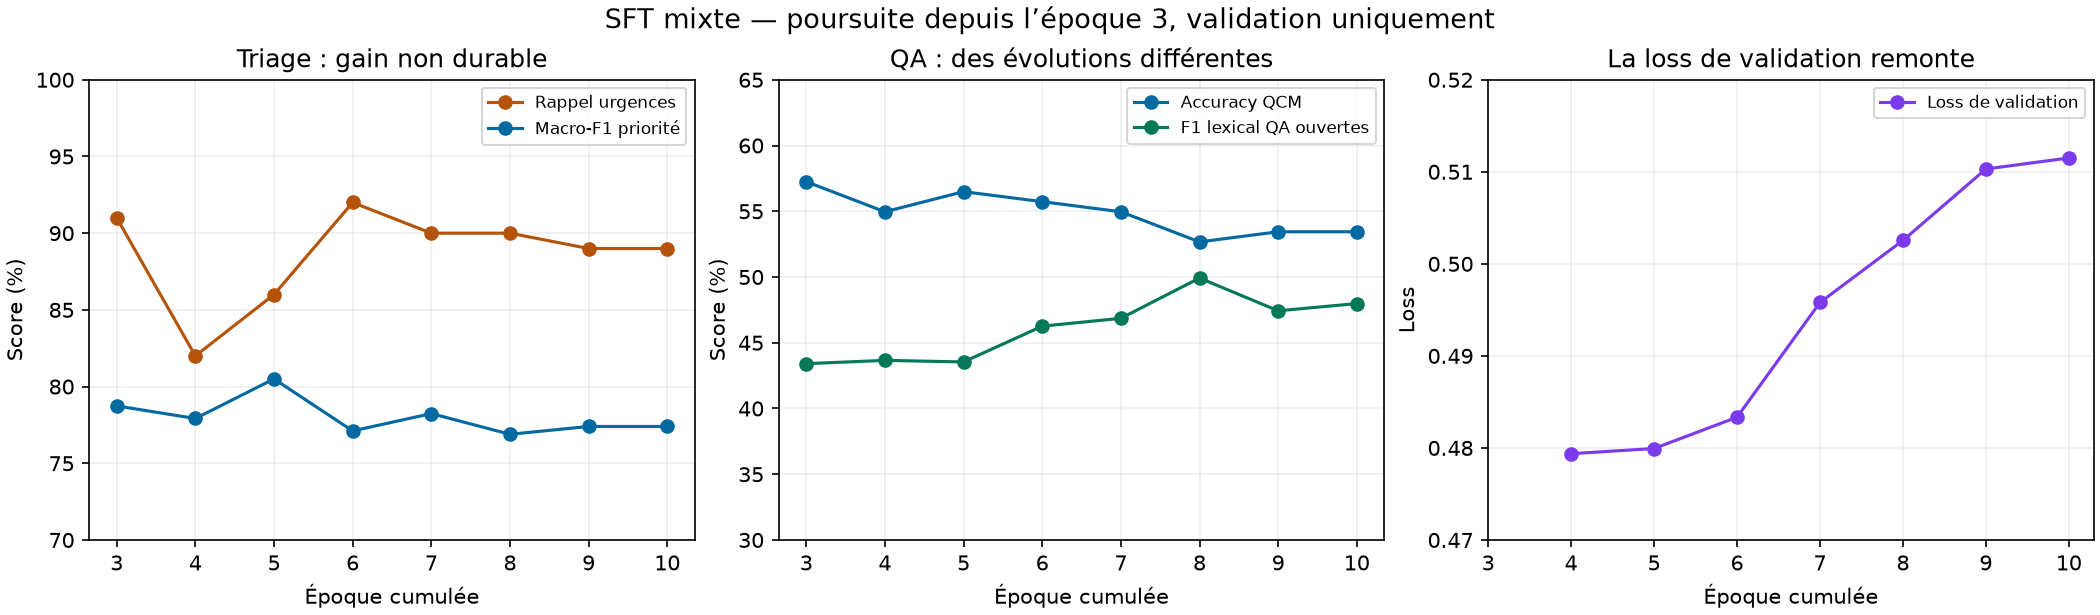